# 09 — The Benchmark Re-Issued: the Safety Pair at Four Operating Points

Two rules came out of notebooks 07 and 08 and have not yet been applied to the
project's headline result:

1. **Report the safety pair, not accuracy.** A classifier that is 60.6 %
   accurate on faulty bearings also false-alarms on 21.8 % of windows from
   healthy bearings it has never seen. Both numbers are the result; one of
   them alone is marketing.
2. **Hold out a healthy bearing too.** Notebooks 04–06 held out damaged
   bearings only, so the false-alarm axis was never measured at all.

This notebook re-issues notebook 05's benchmark under both rules — and does it
at **all four Paderborn operating points**, not just the one every previous
notebook used. Notebook 08 extracted those tables to ask whether an anomaly
baseline survives a change of speed or load; here the question is what the
operating point does to the *diagnosis*.

That turns out to matter more than any feature set, model or calibration
scheme tried so far, and it forces a correction to notebooks 06–08.

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import RandomForestClassifier

OUT = pathlib.Path("../data/processed")
CONDITIONS = ["N15_M07_F10", "N09_M07_F10", "N15_M01_F10", "N15_M07_F04"]
NICE = {"N15_M07_F10": "1500 rpm / 0.7 Nm / 1000 N  (baseline)",
        "N09_M07_F10": "900 rpm / 0.7 Nm / 1000 N  (low speed)",
        "N15_M01_F10": "1500 rpm / 0.1 Nm / 1000 N  (low torque)",
        "N15_M07_F04": "1500 rpm / 0.7 Nm / 400 N  (low radial force)"}
SHORT = {"N15_M07_F10": "baseline", "N09_M07_F10": "900 rpm",
         "N15_M01_F10": "0.1 Nm", "N15_M07_F04": "400 N"}

# Feature tables were built by notebook 08 (same recipe as notebook 07).
D = {c: pd.read_csv(OUT / f"pu_{c}_envelope_orderbands.csv") for c in CONDITIONS}
ds = D["N15_M07_F10"]
FUND = ["Env_BPFO_dB", "Env_BPFI_dB", "Env_fr_dB"]
HEALTHY = sorted(ds.loc[ds["Domain"] == "healthy", "Code"].unique())
REAL = sorted(ds.loc[ds["Domain"] == "real", "Code"].unique())
LABEL = ds.drop_duplicates("Code").set_index("Code")[["Condition", "Domain"]]
RF_KW = dict(n_estimators=300, random_state=0, n_jobs=-1)
N_WIN, N_RUN = 15, 20

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
CLASS_COLOR = {"Healthy": MUTED, "OR": C_BLUE, "IR": C_ORANGE}
HEAT = LinearSegmentedColormap.from_list("heat", [SURFACE, "#f6d3c2", C_ORANGE, "#8c3311"])


def evaluate(train_cond, test_cond, feats=FUND):
    """Leave-one-healthy-bearing-out. Missed-fault per real bearing + false alarm."""
    tr_d, te_d = D[train_cond], D[test_cond]
    mw = {c: [] for c in REAL}
    mr = {c: [] for c in REAL}
    acc = {c: [] for c in REAL}
    faw, far = [], []
    for h in HEALTHY:
        tr = tr_d[((tr_d["Domain"] == "healthy") & (tr_d["Code"] != h))
                  | (tr_d["Domain"] == "artificial")]
        m = RandomForestClassifier(**RF_KW).fit(tr[feats], tr["Condition"])
        alarm = m.predict(te_d[te_d["Code"] == h][feats]) != "Healthy"
        faw.append(alarm.mean())
        far.append((alarm.reshape(N_RUN, N_WIN).mean(axis=1) > 0.5).mean())
        for r in REAL:
            p = m.predict(te_d[te_d["Code"] == r][feats])
            mw[r].append((p == "Healthy").mean())
            mr[r].append(((p == "Healthy").reshape(N_RUN, N_WIN).mean(axis=1) > 0.5).mean())
            acc[r].append((p == LABEL.loc[r, "Condition"]).mean())
    per = pd.DataFrame({"missed_window": {k: np.mean(v) for k, v in mw.items()},
                        "missed_recording": {k: np.mean(v) for k, v in mr.items()},
                        "accuracy": {k: np.mean(v) for k, v in acc.items()}}).join(LABEL)
    return per, np.mean(faw), np.mean(far)


print(f"{len(HEALTHY)} healthy + {len(REAL)} real bearings, "
      f"{len(CONDITIONS)} operating points, features = {FUND}")

6 healthy + 11 real bearings, 4 operating points, features = ['Env_BPFO_dB', 'Env_BPFI_dB', 'Env_fr_dB']


## Experiment 1 — the headline, re-issued

For each operating point: train a Random Forest on the eight artificial
bearings plus five of the six healthy ones, and score the sixth healthy
bearing (false alarms) and all eleven real-damage bearings (missed faults),
averaged over the six leave-one-healthy-bearing-out folds. Reported at window
level and at recording level (majority of the 15 windows in one 4-second
record).

The `accuracy` column is notebook 05's old metric, kept only so the two can be
read against each other.

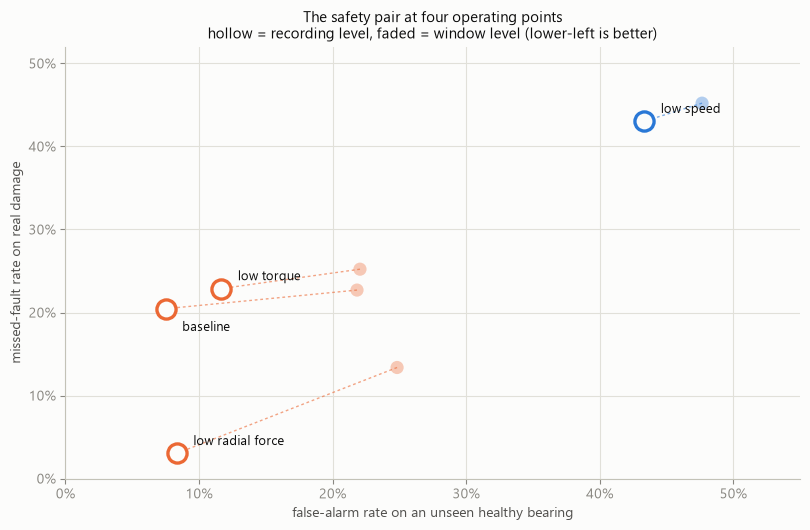

,missed_window,missed_recording,false_alarm_window,false_alarm_recording,accuracy,bearings_over_50pct
condition,,,,,,
baseline,22.7%,20.5%,21.8%,7.5%,61.7%,2
900 rpm,45.2%,43.0%,47.7%,43.3%,39.6%,5
0.1 Nm,25.2%,22.9%,22.1%,11.7%,62.4%,2
400 N,13.4%,3.0%,24.8%,8.3%,63.2%,0


In [2]:
rows, same = [], {}
for c in CONDITIONS:
    per, faw, far = evaluate(c, c)
    same[c] = per
    rows.append(dict(condition=SHORT[c],
                     missed_window=per["missed_window"].mean(),
                     missed_recording=per["missed_recording"].mean(),
                     false_alarm_window=faw, false_alarm_recording=far,
                     accuracy=per["accuracy"].mean(),
                     bearings_over_50pct=int((per["missed_recording"] > 0.5).sum())))
headline = pd.DataFrame(rows).set_index("condition")

fig, ax = plt.subplots(figsize=(8.2, 5.4))
for c in CONDITIONS:
    r = headline.loc[SHORT[c]]
    bad = c == "N09_M07_F10"
    ax.scatter(r["false_alarm_recording"], r["missed_recording"], s=190, zorder=4,
               facecolors=SURFACE, edgecolors=C_BLUE if bad else C_ORANGE, linewidths=2.4)
    ax.scatter(r["false_alarm_window"], r["missed_window"], s=90, zorder=3,
               facecolors=C_BLUE if bad else C_ORANGE, alpha=0.35, edgecolors="none")
    ax.plot([r["false_alarm_window"], r["false_alarm_recording"]],
            [r["missed_window"], r["missed_recording"]],
            color=C_BLUE if bad else C_ORANGE, lw=1, ls=(0, (2, 2)), alpha=0.6, zorder=2)
    dx, dy = (12, -16) if c == "N15_M07_F10" else (12, 6)
    ax.annotate(NICE[c].split("  (")[1][:-1], (r["false_alarm_recording"], r["missed_recording"]),
                textcoords="offset points", xytext=(dx, dy), fontsize=9.5, color=INK)
ax.set_xlim(0, 0.55)
ax.set_ylim(0, 0.52)
ax.set_xticks([0, .1, .2, .3, .4, .5], ["0%", "10%", "20%", "30%", "40%", "50%"])
ax.set_yticks([0, .1, .2, .3, .4, .5], ["0%", "10%", "20%", "30%", "40%", "50%"])
ax.set_xlabel("false-alarm rate on an unseen healthy bearing")
ax.set_ylabel("missed-fault rate on real damage")
ax.set_title("The safety pair at four operating points\n"
             "hollow = recording level, faded = window level (lower-left is better)",
             fontsize=11)
plt.tight_layout()
plt.show()
headline.style.format({c: "{:.1%}" for c in headline.columns if c != "bearings_over_50pct"})

## Reading the re-issued headline

- **The operating point moves the result more than anything else this project
  has tried.** At reduced radial force the missed-fault rate is **13.4 %
  window / 3.0 % recording**, against **22.7 % / 20.5 %** at the baseline
  condition every earlier notebook used — and the false-alarm rate barely
  moves (24.8 % / 8.3 % vs 21.8 % / 7.5 %). That is a genuine improvement in
  the pair, not a threshold slid along a trade-off curve.
- **Low speed is a disaster**: 45.2 % / 43.0 % missed *and* 47.7 % / 43.3 %
  false alarms, with accuracy at 39.6 %. Both axes degrade together, which is
  the signature of a corrupted feature rather than a hard decision — the cause
  is identified in experiment 3.
- **Reduced torque changes almost nothing** (25.2 % / 22.9 % missed) — the
  load parameter that matters is radial force, not torque.
- **Accuracy would have hidden all of this.** It reads 61.7 %, 39.6 %, 62.4 %,
  63.2 % — a 1.5-point spread between the baseline and the reduced-force
  condition, whose recording-level missed-fault rates differ by nearly
  **seven-fold** (20.5 % vs 3.0 %). The old metric is not merely incomplete;
  on this comparison it is actively misleading.

## Experiment 2 — which bearings are invisible, and where?

The pooled numbers above average over bearings that notebooks 05–08 showed are
individually hopeless. The per-bearing view is the one that matters, and with
four operating points it becomes a matrix rather than a list.

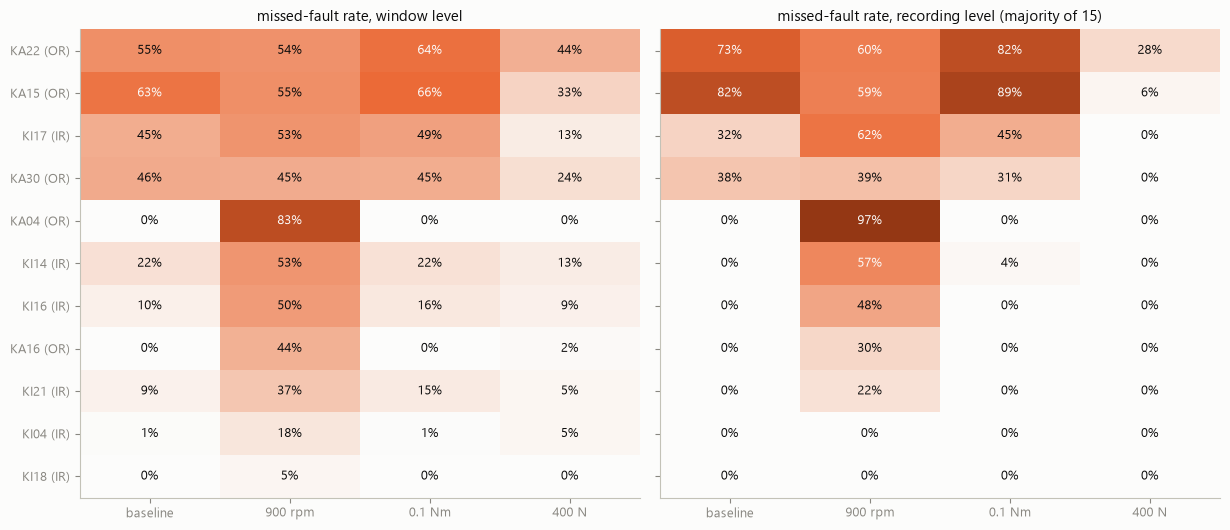

bearings whose recordings are missed >50 % of the time:
  baseline : ['KA15', 'KA22']
  900 rpm  : ['KA04', 'KA15', 'KA22', 'KI14', 'KI17']
  0.1 Nm   : ['KA15', 'KA22']
  400 N    : none

missed >50 % at EVERY operating point: none

the two worst bearings, window vs recording:
      baseline  900 rpm  0.1 Nm  400 N
KA15     0.629    0.547   0.660  0.327
KA22     0.546    0.538   0.638  0.442
KA30     0.459    0.455   0.451  0.236
      baseline  900 rpm  0.1 Nm  400 N
KA15     0.825    0.592   0.892  0.058
KA22     0.725    0.600   0.825  0.275
KA30     0.375    0.392   0.308  0.000


In [3]:
mat_w = pd.DataFrame({SHORT[c]: same[c]["missed_window"] for c in CONDITIONS})
mat_r = pd.DataFrame({SHORT[c]: same[c]["missed_recording"] for c in CONDITIONS})
order = mat_r.mean(axis=1).sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.4), sharey=True)
for ax, mat, title in ((axes[0], mat_w.loc[order], "window level"),
                       (axes[1], mat_r.loc[order], "recording level (majority of 15)")):
    ax.imshow(mat.to_numpy(), cmap=HEAT, vmin=0, vmax=1, aspect="auto")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.iat[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                    color=SURFACE if v > 0.55 else INK)
    ax.set_xticks(range(mat.shape[1]), list(mat.columns), fontsize=9)
    ax.grid(visible=False)
    ax.set_title(f"missed-fault rate, {title}", fontsize=10.5)
axes[0].set_yticks(range(len(order)),
                   [f"{b} ({LABEL.loc[b, 'Condition']})" for b in order], fontsize=9)
plt.tight_layout()
plt.show()

worst = {SHORT[c]: sorted(mat_r.index[mat_r[SHORT[c]] > 0.5]) for c in CONDITIONS}
print("bearings whose recordings are missed >50 % of the time:")
for k, v in worst.items():
    print(f"  {k:9s}: {v if v else 'none'}")
allbad = sorted(mat_r.index[(mat_r > 0.5).all(axis=1)])
print(f"\nmissed >50 % at EVERY operating point: {allbad if allbad else 'none'}")
print("\nthe two worst bearings, window vs recording:")
print(mat_w.loc[["KA15", "KA22", "KA30"]].round(3).to_string())
print(mat_r.loc[["KA15", "KA22", "KA30"]].round(3).to_string())

## Reading the matrix — and a correction to notebooks 06–08

- **No bearing is missed at every operating point.** At the baseline condition
  KA15 and KA22 are missed on 83 % and 73 % of recordings; at reduced radial
  force those fall to **6 % and 28 %**, and *no* bearing exceeds 50 %.
- **This corrects a claim I made three notebooks running.** Notebooks 06, 07
  and 08 concluded that KA15 and KA30 are "physically silent — not
  under-averaged, simply absent" and that no data handling could recover them.
  The mechanism finding was right and survives (experiment 3 shows their BPFO
  margin is still negative at every condition). The **operational conclusion
  drawn from it was wrong**: they are silent *at the operating point those
  notebooks analysed*, and detectable at another. Every one of those notebooks
  examined a single condition, so none of them could have seen this.
- **Read the two panels together, because the recording metric is steep.**
  Recording-level majority flips hard as the window rate crosses 50 %: KA15
  goes 63 % → 33 % at window level but 83 % → 6 % at recording level. The
  window panel is the honest measure of margin; the recording panel is the
  honest measure of what a monitor reports. KA15 at reduced force is
  *detected*, but it is not comfortable — a third of its windows still read
  healthy.
- **Low speed makes previously easy bearings hard**: KA04, a 0 %-missed
  bearing everywhere else, is missed on 97 % of recordings at 900 rpm.

## Experiment 3 — why does the operating point matter this much?

Two effects to separate: something that helps at reduced radial force, and
something that breaks at low speed. Both are visible in the raw feature
margins — each bearing's median level at the three fundamentals, measured
against the **loudest healthy bearing** at that same operating point, which is
the bar a classifier actually has to clear.

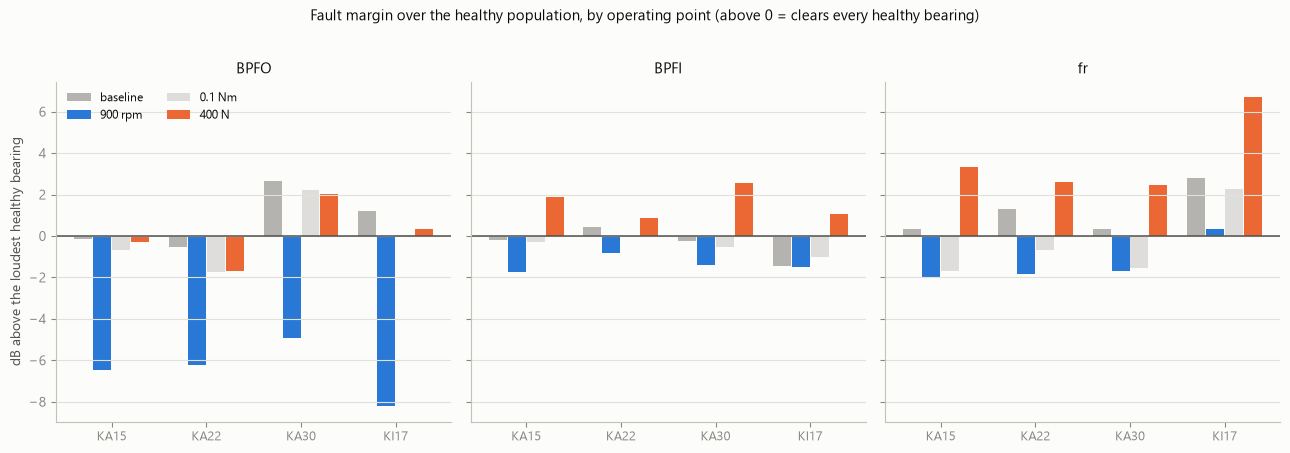

healthy population level at each fundamental (median over 6 bearings):
             baseline  900 rpm  0.1 Nm  400 N
Env_BPFO_dB      1.57     9.25    1.79   1.58
Env_BPFI_dB      0.62    -0.10    0.88   0.16
Env_fr_dB        2.28     2.98    3.09   2.51

loudest healthy bearing (the bar to clear):
             baseline  900 rpm  0.1 Nm  400 N
Env_BPFO_dB      3.13    12.52    3.96   3.88
Env_BPFI_dB      3.01     2.30    2.75   1.64
Env_fr_dB        4.30     5.09    5.96   4.27

shaft rate: {'baseline': 24.99, '900 rpm': 15.0, '0.1 Nm': 24.99, '400 N': 24.99}
BPFO in Hz: {'baseline': 76.7, '900 rpm': 46.1, '0.1 Nm': 76.7, '400 N': 76.7}  <- rig harmonic family sits at ~52.7 Hz


In [4]:
def margins(cond):
    h = D[cond][D[cond]["Domain"] == "healthy"].groupby("Code")[FUND].median().max()
    return pd.DataFrame({b: D[cond][D[cond]["Code"] == b][FUND].median() - h
                         for b in REAL}).T


WATCH = ["KA15", "KA22", "KA30", "KI17"]
marg = {c: margins(c) for c in CONDITIONS}

fig, axes = plt.subplots(1, 3, figsize=(13.0, 4.4), sharey=True)
for ax, feat in zip(axes, FUND):
    x = np.arange(len(WATCH))
    for k, c in enumerate(CONDITIONS):
        vals = [marg[c].loc[b, feat] for b in WATCH]
        ax.bar(x + (k - 1.5) * 0.2, vals, width=0.19,
               color=C_BLUE if c == "N09_M07_F10" else
                     (C_ORANGE if c == "N15_M07_F04" else MUTED),
               alpha=(1.0 if c in ("N09_M07_F10", "N15_M07_F04")
                      else (0.62 if c == "N15_M07_F10" else 0.26)),
               label=SHORT[c] if feat == FUND[0] else None)
    ax.axhline(0, color=INK2, lw=1.1)
    ax.set_xticks(x, WATCH, fontsize=9)
    ax.grid(axis="x", visible=False)
    ax.set_title(feat.replace("Env_", "").replace("_dB", ""), fontsize=10.5)
axes[0].set_ylabel("dB above the loudest healthy bearing")
axes[0].legend(fontsize=8.5, loc="upper left", ncol=2)
fig.suptitle("Fault margin over the healthy population, by operating point "
             "(above 0 = clears every healthy bearing)", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

print("healthy population level at each fundamental (median over 6 bearings):")
print(pd.DataFrame({SHORT[c]: D[c][D[c]["Domain"] == "healthy"][FUND].median()
                    for c in CONDITIONS}).round(2).to_string())
print("\nloudest healthy bearing (the bar to clear):")
print(pd.DataFrame({SHORT[c]: D[c][D[c]["Domain"] == "healthy"]
                    .groupby("Code")[FUND].median().max() for c in CONDITIONS})
      .round(2).to_string())
fr = {SHORT[c]: round(float(D[c]["fr_Hz"].median()), 2) for c in CONDITIONS}
print(f"\nshaft rate: {fr}")
print("BPFO in Hz:", {k: round(3.0706 * v, 1) for k, v in fr.items()},
      " <- rig harmonic family sits at ~52.7 Hz")

## Reading the mechanism

**Reduced radial force helps through shaft-rate modulation, not through the
ball-pass line.** KA15's BPFO margin stays negative at every operating point
(−0.15 dB at baseline, −0.31 dB at 400 N) — notebook 06's physics holds, the
dent still does not ring at BPFO. What changes is everything around it:

| KA15 margin over loudest healthy | baseline | 400 N |
|---|---|---|
| BPFO | −0.15 dB | −0.31 dB |
| BPFI | −0.20 dB | **+1.86 dB** |
| shaft rate | +0.32 dB | **+3.35 dB** |

The same pattern holds for KA30 (BPFI −0.24 → +2.57) and KI17 (shaft rate
+2.79 → +6.70). Two things drive it: a lighter radial load narrows the loaded
zone, so a defect entering and leaving it produces **deeper once-per-revolution
modulation**; and the healthy population itself gets quieter (loudest healthy
BPFI drops 3.01 → 1.64 dB), lowering the bar. This is the same shaft-rate
energy notebook 07's attribution table found firing for most detected bearings
— now shown to be *tunable by the operating point*.

**Low speed breaks the BPFO feature outright.** At 900 rpm the shaft rate is
15 Hz, putting BPFO at **46.0 Hz** — right against the ≈ 52.7 Hz rig harmonic
family that notebooks 03 and 06 flagged as envelope contamination. The healthy
population's median BPFO level jumps from 1.57 dB to **9.25 dB** while BPFI
and shaft rate are untouched, and KA04's margin collapses from +15.25 to
+3.18 dB. It is not that low speed is intrinsically hard; it is that on *this
rig* 900 rpm places a bearing fault frequency on top of a structural line.
A different rig would have the collision somewhere else — which is itself the
transferable lesson.

## Experiment 4 — does a model trained at one operating point work at another?

A deployed motor does not sit at one operating point. Train at each condition,
test at each condition, and read the safety pair off the 4 × 4 grid.

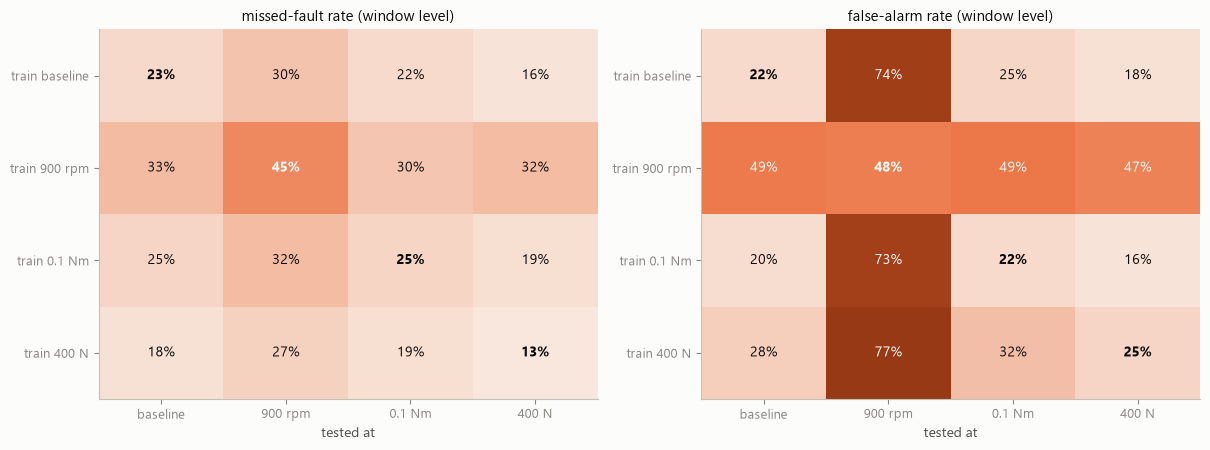

within the 1500 rpm family - missed 13.4%-25.2%, false alarm 16.1%-31.6%
tested at 900 rpm, trained at 1500 - false alarm 73.3%-76.7%


In [5]:
xm = pd.DataFrame(index=[SHORT[c] for c in CONDITIONS], columns=[SHORT[c] for c in CONDITIONS],
                  dtype=float)
xf = xm.copy()
for a in CONDITIONS:
    for b in CONDITIONS:
        per, faw, _ = evaluate(a, b)
        xm.loc[SHORT[a], SHORT[b]] = per["missed_window"].mean()
        xf.loc[SHORT[a], SHORT[b]] = faw

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6))
for ax, mat, title in ((axes[0], xm, "missed-fault rate"),
                       (axes[1], xf, "false-alarm rate")):
    ax.imshow(mat.to_numpy().astype(float), cmap=HEAT, vmin=0, vmax=0.8, aspect="auto")
    for i in range(4):
        for j in range(4):
            v = mat.iat[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=10,
                    color=SURFACE if v > 0.45 else INK,
                    fontweight="bold" if i == j else "normal")
    ax.set_xticks(range(4), list(mat.columns), fontsize=9)
    ax.set_yticks(range(4), [f"train {c}" for c in mat.index], fontsize=9)
    ax.grid(visible=False)
    ax.set_title(f"{title} (window level)", fontsize=10.5)
axes[0].set_xlabel("tested at")
axes[1].set_xlabel("tested at")
plt.tight_layout()
plt.show()

fam = [SHORT[c] for c in CONDITIONS if c != "N09_M07_F10"]
print(f"within the 1500 rpm family - missed {xm.loc[fam, fam].to_numpy().min():.1%}"
      f"-{xm.loc[fam, fam].to_numpy().max():.1%}, "
      f"false alarm {xf.loc[fam, fam].to_numpy().min():.1%}"
      f"-{xf.loc[fam, fam].to_numpy().max():.1%}")
print(f"tested at 900 rpm, trained at 1500 - false alarm "
      f"{xf.loc[fam, '900 rpm'].min():.1%}-{xf.loc[fam, '900 rpm'].max():.1%}")

## Reading the transfer grid

- **Speed is the barrier; load and torque are not.** Inside the 1500 rpm
  family every train/test pairing lands at 13.4–25.2 % missed and 16.1–31.6 %
  false alarms — no worse than training on the matching condition. A model
  learned at one load transfers to another load essentially for free.
- **Crossing the speed boundary destroys the false-alarm axis**: a model
  trained at 1500 rpm and tested at 900 rpm false-alarms on **73–77 %** of
  healthy windows. This is the supervised twin of notebook 08's finding that a
  per-unit anomaly baseline reused at 900 rpm false-alarms on 99.8 % — two
  entirely different channels, same boundary, same cause.
- **Training at 900 rpm is bad everywhere** (30–45 % missed wherever it is
  tested): a model fitted on a contaminated feature learns the contamination.
- Practical rule: **one model per speed bin, shared across load.** Same
  conclusion notebook 08 reached for baselines, now for classifiers too.

## Experiment 5 — is it better to sweep operating points, or to choose one?

If reduced radial force reveals bearings the baseline condition hides, an
obvious next thought is to run the motor through several operating points and
combine the verdicts. Worth testing rather than assuming: each extra point is
another chance to alarm on a healthy unit.

Combination rules take the recording-level decision at each operating point
and require *k* of them to agree.

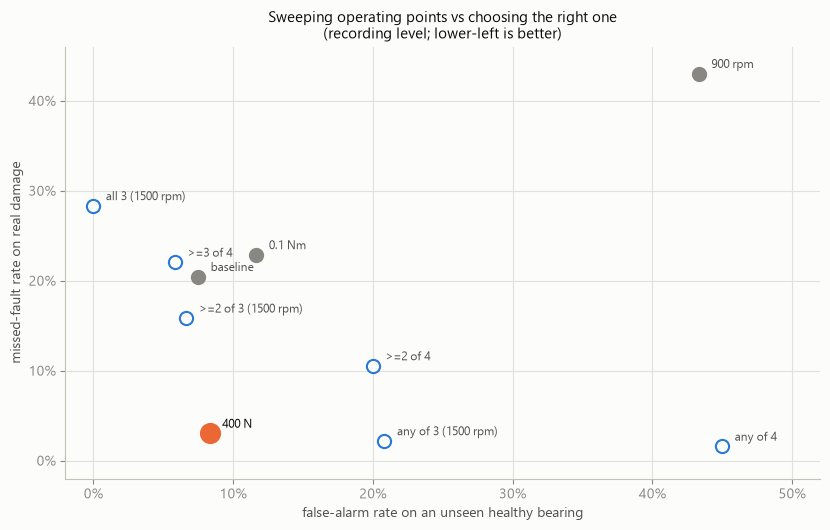

,missed,false_alarm,worst
rule,,,
single: baseline,20.5%,7.5%,82.5%
single: 900 rpm,43.0%,43.3%,96.7%
single: 0.1 Nm,22.9%,11.7%,89.2%
single: 400 N,3.0%,8.3%,27.5%
any of 4,1.6%,45.0%,15.0%
>=2 of 4,10.5%,20.0%,50.0%
>=3 of 4,22.0%,5.8%,87.5%
any of 3 (1500 rpm),2.2%,20.8%,18.3%
>=2 of 3 (1500 rpm),15.8%,6.7%,80.0%


In [6]:
rec = {}
for c in CONDITIONS:
    d = D[c]
    for h in HEALTHY:
        tr = d[((d["Domain"] == "healthy") & (d["Code"] != h)) | (d["Domain"] == "artificial")]
        m = RandomForestClassifier(**RF_KW).fit(tr[FUND], tr["Condition"])
        for b in [h] + REAL:
            p = m.predict(d[d["Code"] == b][FUND]) != "Healthy"
            rec[(c, h, b)] = p.reshape(N_RUN, N_WIN).mean(axis=1) > 0.5


def rule(conds, k):
    miss, fa = {b: [] for b in REAL}, []
    for h in HEALTHY:
        fa.append((np.sum([rec[(c, h, h)] for c in conds], axis=0) >= k).mean())
        for b in REAL:
            v = np.sum([rec[(c, h, b)] for c in conds], axis=0)
            miss[b].append(1 - (v >= k).mean())
    per = {b: np.mean(v) for b, v in miss.items()}
    return np.mean(list(per.values())), np.mean(fa), per


FAMILY = [c for c in CONDITIONS if c != "N09_M07_F10"]
RULES = ([(f"single: {SHORT[c]}", [c], 1) for c in CONDITIONS]
         + [("any of 4", CONDITIONS, 1), (">=2 of 4", CONDITIONS, 2),
            (">=3 of 4", CONDITIONS, 3), ("any of 3 (1500 rpm)", FAMILY, 1),
            (">=2 of 3 (1500 rpm)", FAMILY, 2), ("all 3 (1500 rpm)", FAMILY, 3)])
rows, pers = [], {}
for name, cs, k in RULES:
    m, f, per = rule(cs, k)
    pers[name] = per
    rows.append(dict(rule=name, missed=m, false_alarm=f, worst=max(per.values())))
sweep = pd.DataFrame(rows).set_index("rule")

fig, ax = plt.subplots(figsize=(8.4, 5.4))
for name, r in sweep.iterrows():
    single = name.startswith("single")
    best = name == "single: 400 N"
    ax.scatter(r["false_alarm"], r["missed"], s=170 if best else 90, zorder=4 if best else 3,
               facecolors=C_ORANGE if best else (MUTED if single else SURFACE),
               edgecolors=C_ORANGE if best else (MUTED if single else C_BLUE),
               linewidths=2.2 if best else 1.5)
    ax.annotate(name.replace("single: ", ""), (r["false_alarm"], r["missed"]),
                textcoords="offset points", xytext=(9, 4), fontsize=8.5,
                color=INK if best else INK2)
ax.set_xlim(-0.02, 0.52)
ax.set_ylim(-0.02, 0.46)
ax.set_xticks([0, .1, .2, .3, .4, .5], ["0%", "10%", "20%", "30%", "40%", "50%"])
ax.set_yticks([0, .1, .2, .3, .4], ["0%", "10%", "20%", "30%", "40%"])
ax.set_xlabel("false-alarm rate on an unseen healthy bearing")
ax.set_ylabel("missed-fault rate on real damage")
ax.set_title("Sweeping operating points vs choosing the right one\n"
             "(recording level; lower-left is better)", fontsize=11)
plt.tight_layout()
plt.show()
sweep.style.format("{:.1%}")

## Reading the sweep

- **Choosing beats sweeping.** Running only at reduced radial force gives
  **3.0 % missed / 8.3 % false alarms**. The best sweep, "any of 3", gives
  2.2 % missed but **20.8 %** false alarms — 0.8 points of missed fault bought
  for 12.5 points of false alarm. Every other rule is worse on both axes or on
  one without compensating on the other; "all 3" reaches 0 % false alarms but
  misses 28.3 % of faults.
- The reason is straightforward once stated: the extra operating points are
  not independent looks at the fault, but they *are* nearly independent
  chances to trip on a healthy unit. OR-combination compounds the false-alarm
  rate faster than it recovers detections.
- **At 400 N only two bearings are missed at all** — KA22 (27.5 %) and KA15
  (5.8 %); the other nine are at 0.0 %. The sweep improves KA22 to 18.3 % and
  leaves KA15 unchanged.
- Deployment reading: the operating point is a **design variable for
  diagnosability**, and the design move is to pick a good one — ideally a
  scheduled low-load diagnostic window — rather than to average over many.

## Findings (executed 2026-08-19)

1. **The project's headline, re-issued under both new rules.** At the baseline
   operating point every notebook has used, the pair is **22.7 % window /
   20.5 % recording missed faults against 21.8 % / 7.5 % false alarms on
   unseen healthy bearings** (accuracy 61.7 %). This replaces notebook 05's
   "60.6 % ± 36.4 accuracy" as the number this project reports.
2. **The operating point is the largest lever found so far — larger than
   features, model family, mixing strategy or calibration.** At reduced radial
   force (400 N instead of 1000 N) the missed-fault rate falls to **13.4 % /
   3.0 %** while false alarms stay flat (24.8 % / 8.3 %). Reduced torque
   changes little; the load parameter that matters is radial force.
3. **Correction to notebooks 06–08.** Those notebooks concluded KA15 and KA30
   were physically undetectable and should be scoped out. The *mechanism*
   claim survives — their BPFO margin is negative at all four operating points
   — but the operational conclusion does not: at 400 N, KA15's recordings are
   missed **6 %** of the time (from 83 %), KA30's **0 %** (from 38 %), and at
   that operating point no bearing is missed on more than half its recordings
   at all. (At 900 rpm five bearings still are — that condition is worse, not
   better.)
   All three notebooks examined one operating point, so none could have seen
   this. **The pending pitting-only scope decision should not be taken.**
4. **The mechanism is shaft-rate modulation, not the ball-pass line.** At
   reduced load KA15's BPFO margin stays negative (−0.15 → −0.31 dB) while its
   BPFI margin goes −0.20 → **+1.86 dB** and its shaft-rate margin +0.32 →
   **+3.35 dB**; the loudest healthy bearing also quietens (BPFI 3.01 →
   1.64 dB). A lighter radial load narrows the loaded zone and deepens
   once-per-revolution modulation.
5. **Low speed fails for a rig-specific reason, and fails on both axes**
   (45.2 % missed *and* 47.7 % false alarms). At 900 rpm BPFO lands at
   **46.0 Hz**, against the ≈ 52.7 Hz rig harmonic family: the healthy
   population's median BPFO level rises 1.57 → **9.25 dB** while BPFI and
   shaft rate are untouched. The transferable lesson is to check fault
   frequencies against structural lines per rig and speed, not that low speed
   is intrinsically hard.
6. **One model per speed bin, shared across load.** Within the 1500 rpm family
   all train/test pairings hold at 13.4–25.2 % missed and 16.1–31.6 % false
   alarms; a 1500 rpm model tested at 900 rpm false-alarms on **73–77 %** of
   healthy windows. Notebook 08 found the identical boundary for unsupervised
   baselines (99.8 %) — two channels, same conclusion.
7. **Choosing an operating point beats sweeping several.** Reduced force alone
   gives 3.0 % / 8.3 %; the best OR-combination gives 2.2 % / **20.8 %**.
   Extra operating points add near-independent chances to false-alarm faster
   than they add detections.
8. **Accuracy would have concealed the main result**: it spans only
   61.7–63.2 % across the three 1500 rpm conditions whose recording-level
   missed-fault rates differ nearly seven-fold (20.5 % vs 3.0 %).
9. **Caveats:** one rig, one bearing type, and the load comparison is a single
   pair (1000 N vs 400 N) — the direction is physically motivated but not a
   dose-response curve. The recording-level metric is steep near a 50 % window
   rate, so it exaggerates small margin changes; both levels are reported
   throughout. Single classifier family (RF) and the three envelope
   fundamentals, per notebooks 05 and 07.